**Chapter 18 – Autoencoders, GANs, and Diffusion Models**

_This notebook contains all the sample code and solutions to the exercises in chapter 18._

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/PGupta-Git/handson-mlp/blob/polars_integration/18_autoencoders_gans_and_diffusion_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
  <td>
    <a target="_blank" href="https://kaggle.com/kernels/welcome?src=https://github.com/PGupta-Git/handson-mlp/blob/polars_integration/18_autoencoders_gans_and_diffusion_models.ipynb"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" /></a>
  </td>
</table>

# Setup

This project requires Python 3.10 or above:

In [1]:
import sys

assert sys.version_info >= (3, 11)

Are we using Colab or Kaggle?

In [2]:
IS_COLAB = "google.colab" in sys.modules
IS_KAGGLE = "kaggle_secrets" in sys.modules

If using Colab, the TorchMetrics library is not pre-installed so we must install it manually:

In [3]:
if IS_COLAB:
    %pip install -q torchmetrics

We also need PyTorch ≥ 2.6.0:

In [4]:
from packaging.version import Version
import torch

assert Version(torch.__version__) >= Version("2.6.0")

This chapter can be very slow without a hardware accelerator, so if we can find one, let's use it:

In [5]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cuda'

Let's issue a warning if there's no hardware accelerator available:

In [6]:
if device == "cpu":
    print("Neural nets can be very slow without a hardware accelerator.")
    if IS_COLAB:
        print("Go to Runtime > Change runtime and select a GPU hardware accelerator.")
    if IS_KAGGLE:
        print("Go to Settings > Accelerator and select GPU.")

As we did in earlier chapters, let's define the default font sizes to make the figures prettier:

In [7]:
import matplotlib.pyplot as plt

plt.rc("font", size=14)
plt.rc("axes", labelsize=14, titlesize=14)
plt.rc("legend", fontsize=14)
plt.rc("xtick", labelsize=10)
plt.rc("ytick", labelsize=10)

We will also be using the same `train()` and `evaluate_tm()` functions as in previous chapters, but with a couple tweaks to the `train()` function:
* Gradient clipping using `torch.nn.utils.clip_grad_norm_()`
* Support for named tuples outputs containing an `output` field (see the lines: `y_pred = y_pred.output if...`)

In [8]:
import torchmetrics


def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            if isinstance(y_pred, tuple):
                y_pred = y_pred.output
            metric.update(y_pred, y_batch)
    return metric.compute()


def train(
    model,
    optimizer,
    loss_fn,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    patience=2,
    factor=0.5,
    epoch_callback=None,
):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=patience, factor=factor
    )
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        if epoch_callback is not None:
            epoch_callback(model, epoch)
        for index, (X_batch, y_batch) in enumerate(train_loader):
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad()
            if isinstance(y_pred, tuple):
                y_pred = y_pred.output
            metric.update(y_pred, y_batch)
            train_metric = metric.compute().item()
            print(f"\rBatch {index + 1}/{len(train_loader)}", end="")
            print(f", loss={total_loss / (index + 1):.4f}", end="")
            print(f", {train_metric=:.3f}", end="")
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(train_metric)
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        print(
            f"\rEpoch {epoch + 1}/{n_epochs},                      "
            f"train loss: {history['train_losses'][-1]:.4f}, "
            f"train metric: {history['train_metrics'][-1]:.3}, "
            f"valid metric: {history['valid_metrics'][-1]:.3}"
        )
    return history

# Performing PCA with an Undercomplete Linear Autoencoder

Let's build the Autoencoder...

In [9]:
import torch
import torch.nn as nn

torch.manual_seed(42)
encoder = nn.Linear(3, 2)
decoder = nn.Linear(2, 3)
autoencoder = nn.Sequential(encoder, decoder).to(device)

Now let's generate the same 3D dataset as we used in Chapter 7:

In [10]:
# extra code – builds the same 3D dataset as in Chapter 7

import numpy as np
from scipy.spatial.transform import Rotation


def generate_data(m, seed=42):
    X = np.zeros((m, 3))  # initialize 3D dataset
    rng = np.random.default_rng(seed)
    angles = (rng.random(m) ** 3 + 0.5) * 2 * np.pi  # uneven distribution
    X[:, 0], X[:, 1] = np.cos(angles), np.sin(angles) * 0.5  # oval
    X += 0.28 * rng.standard_normal((m, 3))  # add more noise
    X = Rotation.from_rotvec([np.pi / 29, -np.pi / 20, np.pi / 4]).apply(X)
    X += [0.2, 0, 0.2]  # shift a bit
    return torch.from_numpy(X.astype(np.float32))

In [11]:
from torch.utils.data import DataLoader, TensorDataset

X_train = generate_data(60, seed=42)
train_set = TensorDataset(X_train, X_train)
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)

In [12]:
X_valid = generate_data(500, seed=43)
valid_set = TensorDataset(X_valid, X_valid)
valid_loader = DataLoader(valid_set, batch_size=32)

In [13]:
import torchmetrics

torch.manual_seed(42)
optimizer = torch.optim.NAdam(autoencoder.parameters(), lr=0.2)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train(
    autoencoder, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=20
)

Epoch 1/20,                      train loss: 0.1621, train metric: 0.406, valid metric: 0.309
Epoch 2/20,                      train loss: 0.0697, train metric: 0.264, valid metric: 0.297
Epoch 3/20,                      train loss: 0.0644, train metric: 0.253, valid metric: 0.324
Epoch 4/20,                      train loss: 0.0935, train metric: 0.303, valid metric: 0.45
Epoch 5/20,                      train loss: 0.1088, train metric: 0.336, valid metric: 0.245
Epoch 6/20,                      train loss: 0.0415, train metric: 0.203, valid metric: 0.235
Epoch 7/20,                      train loss: 0.0426, train metric: 0.205, valid metric: 0.273
Epoch 8/20,                      train loss: 0.0470, train metric: 0.218, valid metric: 0.211
Epoch 9/20,                      train loss: 0.0314, train metric: 0.179, valid metric: 0.213
Epoch 10/20,                      train loss: 0.0300, train metric: 0.174, valid metric: 0.209
Epoch 11/20,                      train loss: 0.0300, train 

In [14]:
codings = encoder(X_train.to(device))

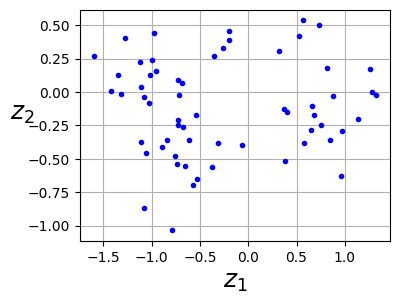

In [15]:
fig = plt.figure(figsize=(4, 3))
codings_np = codings.cpu().detach().numpy()
plt.plot(codings_np[:, 0], codings_np[:, 1], "b.")
plt.xlabel("$z_1$", fontsize=18)
plt.ylabel("$z_2$", fontsize=18, rotation=0)
plt.grid(True)

plt.show()

# Stacked Autoencoders

## Implementing a Stacked Autoencoder Using PyTorch

Let's build and train a stacked Autoencoder with 3 hidden layers and 1 output layer (i.e., 2 stacked Autoencoders).

In [16]:
torch.manual_seed(42)  # extra code – ensures reproducibility

stacked_encoder = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1 * 28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 32),
    nn.ReLU(),
)
stacked_decoder = nn.Sequential(
    nn.Linear(32, 128),
    nn.ReLU(),
    nn.Linear(128, 1 * 28 * 28),
    nn.Sigmoid(),
    nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
)
stacked_ae = nn.Sequential(stacked_encoder, stacked_decoder).to(device)

Let's load the fashion MNIST dataset, and split it into a training set, a validation set, and a test set:

In [17]:
import torchvision
import torchvision.transforms.v2 as T

toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

train_and_valid_data = torchvision.datasets.FashionMNIST(
    root="datasets", train=True, download=True, transform=toTensor
)
test_data = torchvision.datasets.FashionMNIST(
    root="datasets", train=False, download=True, transform=toTensor
)

torch.manual_seed(42)
train_data, valid_data = torch.utils.data.random_split(
    train_and_valid_data, [55_000, 5_000]
)

In [18]:
from torch.utils.data import Dataset


class AutoencoderDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        x, _ = self.base_dataset[idx]
        return x, x


train_loader = DataLoader(AutoencoderDataset(train_data), batch_size=32, shuffle=True)
valid_loader = DataLoader(AutoencoderDataset(valid_data), batch_size=32)
test_loader = DataLoader(AutoencoderDataset(test_data), batch_size=32)

In [19]:
optimizer = torch.optim.NAdam(stacked_ae.parameters(), lr=0.01)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train(
    stacked_ae, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=10
)

Batch 80/1719, loss=0.0597, train_metric=0.244

Batch 162/1719, loss=0.0472, train_metric=0.217

Batch 242/1719, loss=0.0413, train_metric=0.203

Batch 323/1719, loss=0.0377, train_metric=0.194

Batch 403/1719, loss=0.0355, train_metric=0.188

...

Batch 1528/1719, loss=0.0144, train_metric=0.120

Batch 1615/1719, loss=0.0144, train_metric=0.120

Batch 1704/1719, loss=0.0144, train_metric=0.120

Batch 1719/1719, loss=0.0144, train_metric=0.120

Epoch 10/10,                      train loss: 0.0144, train metric: 0.12, valid metric: 0.121


## Visualizing the Reconstructions

This function processes a few validation images through the autoencoder and displays the original images and their reconstructions:

In [20]:
def plot_image(image):
    plt.imshow(image.permute(1, 2, 0).cpu(), cmap="binary")
    plt.axis("off")


def plot_reconstructions(model, images, n_images=5):
    images = images[:n_images]
    with torch.no_grad():
        y_pred = model(images.to(device))
    if isinstance(y_pred, tuple):
        y_pred = y_pred.output
    fig = plt.figure(figsize=(len(images) * 1.5, 3))
    for idx in range(len(images)):
        plt.subplot(2, len(images), 1 + idx)
        plot_image(images[idx])
        plt.subplot(2, len(images), 1 + len(images) + idx)
        plot_image(y_pred[idx])

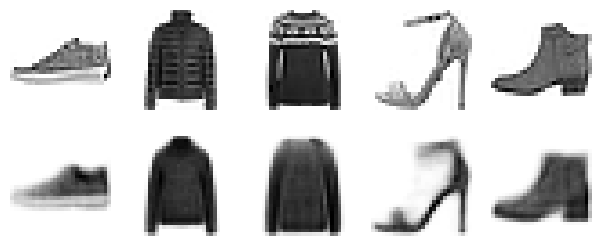

In [21]:
X_valid = torch.stack([x for x, _ in valid_data])
plot_reconstructions(stacked_ae, X_valid)

plt.show()

The reconstructions look fuzzy, but remember that the images were compressed down to just 32 numbers, instead of 784.

## Using AutoEncoders for Anomaly Detection

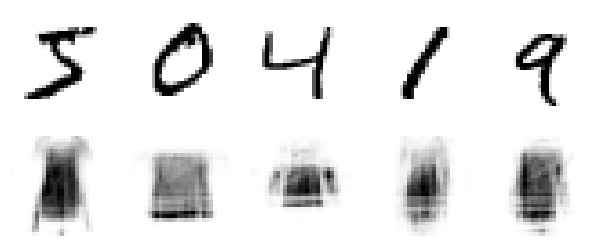

In [22]:
torch.manual_seed(42)
mnist_data = torchvision.datasets.MNIST(
    root="datasets", train=True, download=True, transform=toTensor
)
mnist_images = torch.stack([mnist_data[i][0] for i in range(X_valid.size(0))])
plot_reconstructions(stacked_ae, images=mnist_images)

plt.show()

In [23]:
images = mnist_images.to(device)
with torch.no_grad():
    y_pred = stacked_ae(images)
    recon_loss = torch.nn.functional.mse_loss(y_pred, images)

recon_loss

tensor(0.0607, device='cuda:0')

If we compare the reconstruction losses for all Fashion MNIST images and all MNIST images, we can see that the latter are much higher on average:

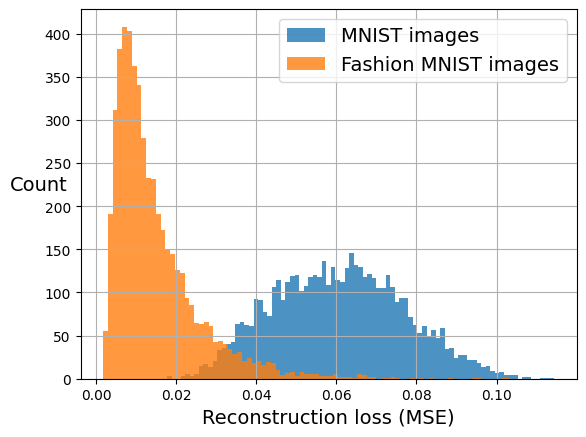

In [24]:
import torch.nn.functional as F


def compute_reconstruction_losses(X, device):
    X = X.to(device)
    with torch.no_grad():
        y_pred = stacked_ae(X)
        return (
            F.mse_loss(y_pred, X, reduction="none")
            .view(X.size(0), -1)
            .mean(dim=1)
            .cpu()
        )


recon_losses_mnist = compute_reconstruction_losses(mnist_images, device)
recon_losses_fashion_mnist = compute_reconstruction_losses(X_valid, device)

plt.hist(recon_losses_mnist, bins=85, alpha=0.8, label="MNIST images")
plt.hist(recon_losses_fashion_mnist, bins=85, alpha=0.8, label="Fashion MNIST images")
plt.xlabel("Reconstruction loss (MSE)")
plt.ylabel("Count", rotation=0)
plt.legend()
plt.grid()

plt.show()

## Visualizing the Fashion MNIST Dataset

In [25]:
from sklearn.manifold import TSNE

with torch.no_grad():
    X_valid_compressed = stacked_encoder(X_valid.to(device))

tsne = TSNE(init="pca", learning_rate="auto", random_state=42)
X_valid_2D = tsne.fit_transform(X_valid_compressed.cpu())

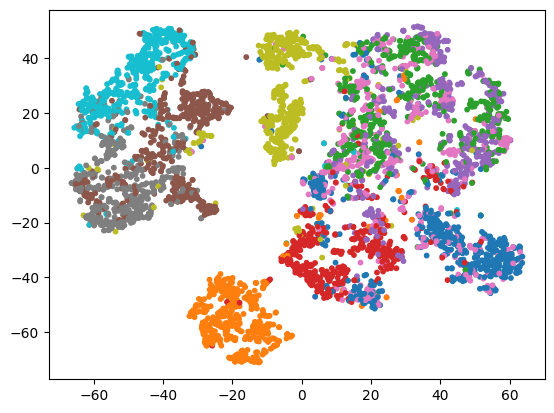

In [26]:
y_valid = torch.tensor([y for _, y in valid_data])

plt.scatter(X_valid_2D[:, 0], X_valid_2D[:, 1], c=y_valid, s=10, cmap="tab10")
plt.show()

Let's make this diagram a bit prettier (adapted from [this Scikit-Learn example](https://scikit-learn.org/stable/auto_examples/manifold/plot_lle_digits.html)):

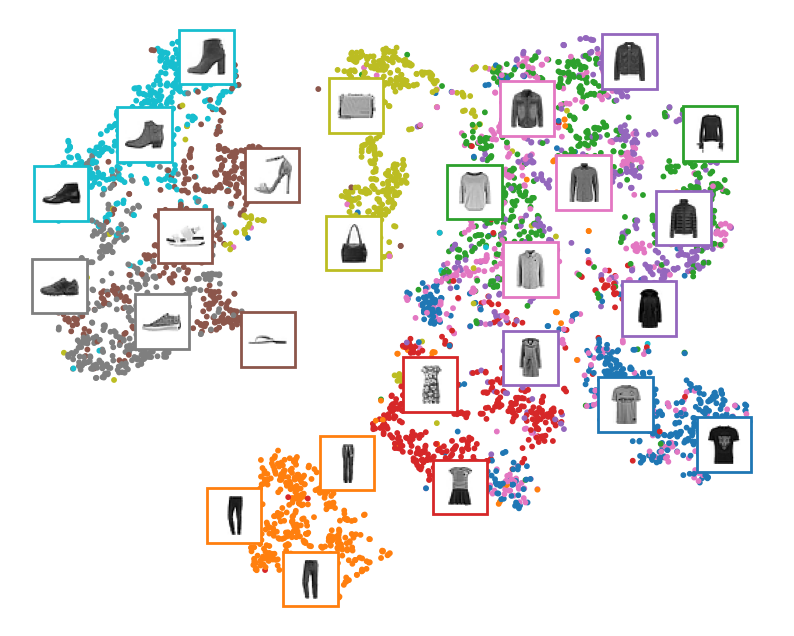

In [27]:
# extra code – beautifies the previous diagram for the book

import matplotlib as mpl

plt.figure(figsize=(10, 8))
cmap = plt.cm.tab10
Z = X_valid_2D
Z = (Z - Z.min()) / (Z.max() - Z.min())  # normalize to the 0-1 range
plt.scatter(Z[:, 0], Z[:, 1], c=y_valid, s=10, cmap=cmap)
image_positions = np.array([[1.0, 1.0]])
for index, position in enumerate(Z):
    dist = ((position - image_positions) ** 2).sum(axis=1)
    if dist.min() > 0.02:  # if far enough from other images
        image_positions = np.r_[image_positions, [position]]
        imagebox = mpl.offsetbox.AnnotationBbox(
            mpl.offsetbox.OffsetImage(X_valid[index].squeeze(dim=0), cmap="binary"),
            position,
            bboxprops={"edgecolor": cmap(y_valid[index]), "lw": 2},
        )
        plt.gca().add_artist(imagebox)

plt.axis("off")

plt.show()

## Tying weights

It is common to tie the weights of the encoder and the decoder, by simply using the transpose of the encoder's weights as the decoder weights. For this, we can use a custom module.

In [28]:
import torch.nn.functional as F


class TiedAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = nn.Linear(1 * 28 * 28, 128)
        self.enc2 = nn.Linear(128, 32)
        self.dec1_bias = nn.Parameter(torch.zeros(128))
        self.dec2_bias = nn.Parameter(torch.zeros(1 * 28 * 28))

    def encode(self, X):
        Z = X.view(-1, 1 * 28 * 28)  # flatten
        Z = F.relu(self.enc1(Z))
        return F.relu(self.enc2(Z))

    def decode(self, X):
        Z = F.relu(F.linear(X, self.enc2.weight.t(), self.dec1_bias))
        Z = F.sigmoid(F.linear(Z, self.enc1.weight.t(), self.dec2_bias))
        return Z.view(-1, 1, 28, 28)  # unflatten

    def forward(self, X):
        return self.decode(self.encode(X))

In [29]:
tied_ae = TiedAutoencoder().to(device)
optimizer = torch.optim.NAdam(tied_ae.parameters(), lr=0.01)
history = train(tied_ae, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=10)

Batch 80/1719, loss=0.0546, train_metric=0.234

Batch 159/1719, loss=0.0445, train_metric=0.211

Batch 242/1719, loss=0.0389, train_metric=0.197

Batch 324/1719, loss=0.0357, train_metric=0.189

Batch 406/1719, loss=0.0334, train_metric=0.183

...

Batch 1508/1719, loss=0.0126, train_metric=0.112

Batch 1589/1719, loss=0.0126, train_metric=0.112

Batch 1675/1719, loss=0.0126, train_metric=0.112

Batch 1719/1719, loss=0.0126, train_metric=0.112

Epoch 10/10,                      train loss: 0.0126, train metric: 0.112, valid metric: 0.113


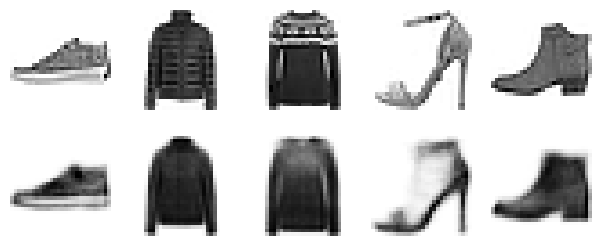

In [30]:
# extra code – plots reconstructions
plot_reconstructions(tied_ae, X_valid)
plt.show()

## Convolutional Autoencoders

Let's build a stacked Autoencoder with 3 hidden layers and 1 output layer (i.e., 2 stacked Autoencoders).

In [31]:
torch.manual_seed(42)  # extra code – ensures reproducibility

conv_encoder = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding="same"),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),  # output: 16 × 14 × 14
    nn.Conv2d(16, 32, kernel_size=3, padding="same"),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),  # output: 32 × 7 × 7
    nn.Conv2d(32, 64, kernel_size=3, padding="same"),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),  # output: 64 × 3 × 3
    nn.Conv2d(64, 32, kernel_size=3, padding="same"),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d((1, 1)),
    nn.Flatten(),
)  # output: 32

conv_decoder = nn.Sequential(
    nn.Linear(32, 16 * 3 * 3),
    nn.Unflatten(dim=1, unflattened_size=(16, 3, 3)),
    nn.ConvTranspose2d(16, 32, kernel_size=3, stride=2),
    nn.ReLU(),
    nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
    nn.ReLU(),
    nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
    nn.Sigmoid(),
)

conv_ae = nn.Sequential(conv_encoder, conv_decoder).to(device)

In [32]:
optimizer = torch.optim.NAdam(conv_ae.parameters(), lr=0.005)
history = train(conv_ae, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=10)

Batch 67/1719, loss=0.0906, train_metric=0.301

Batch 135/1719, loss=0.0801, train_metric=0.283

Batch 203/1719, loss=0.0680, train_metric=0.261

Batch 272/1719, loss=0.0601, train_metric=0.245

Batch 341/1719, loss=0.0546, train_metric=0.234

...

Batch 1528/1719, loss=0.0111, train_metric=0.105

Batch 1597/1719, loss=0.0111, train_metric=0.106

Batch 1666/1719, loss=0.0111, train_metric=0.106

Batch 1719/1719, loss=0.0111, train_metric=0.106

Epoch 10/10,                      train loss: 0.0111, train metric: 0.106, valid metric: 0.106


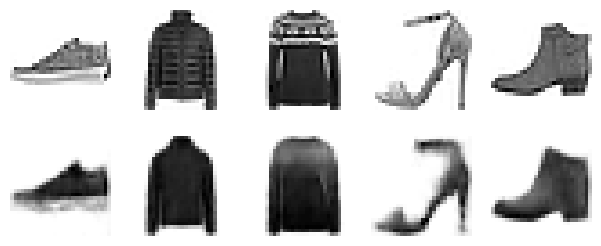

In [33]:
# extra code – shows the reconstructions
plot_reconstructions(conv_ae, X_valid)
plt.show()

# Extra Material – Recurrent Autoencoders

Let's treat each Fashion MNIST image as a sequence of 28 vectors, each with 28 dimensions:

In [34]:
class RecurrentAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder_lstm = nn.LSTM(
            input_size=28, hidden_size=128, num_layers=2, batch_first=True
        )
        self.encoder_proj = nn.Linear(128, 32)  # Compress to latent vector
        self.decoder_lstm = nn.LSTM(input_size=32, hidden_size=128, batch_first=True)
        self.decoder_proj = nn.Linear(128, 28)

    def encode(self, X):  # X shape: [B, 1, 28, 28]
        Z = X.squeeze(dim=1)  # Z shape: [B, 28, 28]
        _, (h_n, _) = self.encoder_lstm(Z)  # h_n shape: [2, B, 100]
        Z = h_n[-1]  # get the hidden state of the last layer: [B, 100]
        return self.encoder_proj(Z)  # [B, 30]

    def decode(self, X):
        Z = X.unsqueeze(dim=1).repeat(1, 28, 1)  # [B, 28, 32]
        Z, _ = self.decoder_lstm(Z)  # [B, 28, 100]
        return F.sigmoid(self.decoder_proj(Z).unsqueeze(dim=1))  # [B, 1, 28, 28]

    def forward(self, X):
        return self.decode(self.encode(X))


torch.manual_seed(42)
recurrent_ae = RecurrentAutoencoder().to(device)

In [35]:
optimizer = torch.optim.NAdam(recurrent_ae.parameters(), lr=1e-3)
history = train(
    recurrent_ae, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=10
)

Batch 26/1719, loss=0.1212, train_metric=0.348

Batch 55/1719, loss=0.1096, train_metric=0.331

Batch 84/1719, loss=0.1051, train_metric=0.324

Batch 113/1719, loss=0.1029, train_metric=0.321

Batch 142/1719, loss=0.1010, train_metric=0.318

...

Batch 1557/1719, loss=0.0121, train_metric=0.110

Batch 1615/1719, loss=0.0121, train_metric=0.110

Batch 1672/1719, loss=0.0121, train_metric=0.110

Batch 1719/1719, loss=0.0121, train_metric=0.110

Epoch 10/10,                      train loss: 0.0121, train metric: 0.11, valid metric: 0.11


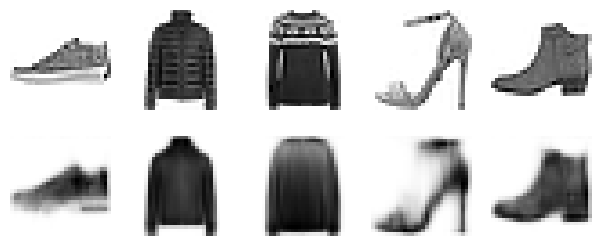

In [36]:
plot_reconstructions(recurrent_ae, X_valid)
plt.show()

# Denoising Autoencoders

Using dropout:

In [37]:
torch.manual_seed(42)  # extra code – ensures reproducibility

dropout_encoder = nn.Sequential(
    nn.Flatten(),
    nn.Dropout(0.5),
    nn.Linear(1 * 28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 128),
    nn.ReLU(),
)
dropout_decoder = nn.Sequential(
    nn.Linear(128, 128),
    nn.ReLU(),
    nn.Linear(128, 1 * 28 * 28),
    nn.Sigmoid(),
    nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
)
dropout_ae = nn.Sequential(dropout_encoder, dropout_decoder).to(device)

In [38]:
optimizer = torch.optim.NAdam(dropout_ae.parameters(), lr=0.01)
history = train(
    dropout_ae, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=10
)

Batch 50/1719, loss=0.0709, train_metric=0.266

Batch 80/1719, loss=0.0625, train_metric=0.250

Batch 134/1719, loss=0.0533, train_metric=0.231

Batch 163/1719, loss=0.0500, train_metric=0.224

Batch 217/1719, loss=0.0456, train_metric=0.214

...

Batch 1498/1719, loss=0.0184, train_metric=0.136

Batch 1576/1719, loss=0.0184, train_metric=0.136

Batch 1654/1719, loss=0.0184, train_metric=0.136

Batch 1719/1719, loss=0.0184, train_metric=0.136

Epoch 10/10,                      train loss: 0.0184, train metric: 0.136, valid metric: 0.131


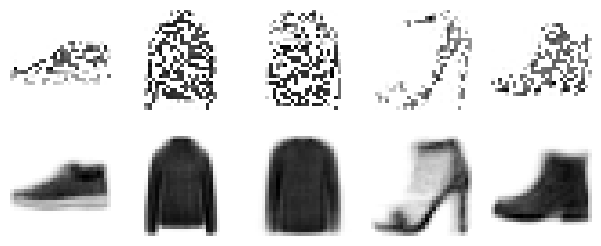

In [39]:
# extra code – this cell generates Figure 18–9
torch.manual_seed(42)
dropout = nn.Dropout(0.5)
plot_reconstructions(dropout_ae, dropout(X_valid))

plt.show()

Instead of using `Dropout`, we can add Gaussian noise:

In [40]:
class GaussianNoise(nn.Module):
    def __init__(self, std):
        super().__init__()
        self.std = std

    def forward(self, X):
        if self.training:  # only add noise during training
            noise = torch.randn_like(X) * self.std
            return X + noise
        return X

In [41]:
torch.manual_seed(42)  # extra code – ensures reproducibility

noise_encoder = nn.Sequential(
    nn.Flatten(),
    GaussianNoise(0.5),
    nn.Linear(1 * 28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 128),
    nn.ReLU(),
)
noise_decoder = nn.Sequential(
    nn.Linear(128, 128),
    nn.ReLU(),
    nn.Linear(128, 1 * 28 * 28),
    nn.Sigmoid(),
    nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
)
noise_ae = nn.Sequential(noise_encoder, noise_decoder).to(device)

In [42]:
optimizer = torch.optim.NAdam(noise_ae.parameters(), lr=0.01)
history = train(noise_ae, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=10)

Batch 36/1719, loss=0.0809, train_metric=0.285

Batch 78/1719, loss=0.0657, train_metric=0.256

Batch 115/1719, loss=0.0581, train_metric=0.241

Batch 160/1719, loss=0.0523, train_metric=0.229

Batch 198/1719, loss=0.0488, train_metric=0.221

...

Batch 1534/1719, loss=0.0208, train_metric=0.144

Batch 1621/1719, loss=0.0208, train_metric=0.144

Batch 1703/1719, loss=0.0208, train_metric=0.144

Batch 1719/1719, loss=0.0208, train_metric=0.144

Epoch 10/10,                      train loss: 0.0208, train metric: 0.144, valid metric: 0.138


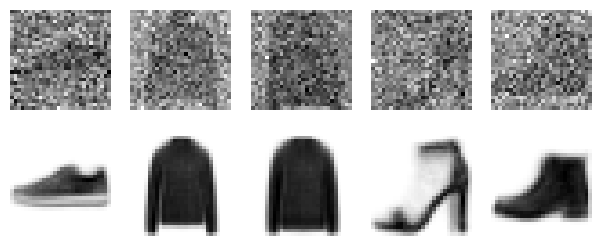

In [43]:
# extra code
torch.manual_seed(42)
noise = GaussianNoise(0.5)
plot_reconstructions(noise_ae, noise(X_valid))
plt.show()

# Sparse Autoencoder

Let's use the sigmoid activation function in the coding layer. Let's also add $\ell_1$ regularization to it: to do this, we make the module return both the reconstructions and the encodings (i.e., the output of the encoder), so the regularization loss can be computed based on the encodings.

In [44]:
from collections import namedtuple

AEOutput = namedtuple("AEOutput", ["output", "codings"])


class SparseAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1 * 28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.Sigmoid(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 1 * 28 * 28),
            nn.Sigmoid(),
            nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
        )

    def forward(self, X):
        codings = self.encoder(X)
        output = self.decoder(codings)
        return AEOutput(output, codings)

In [45]:
def mse_plus_sparsity_loss(
    y_pred, y_target, target_sparsity=0.1, kl_weight=1e-3, eps=1e-8
):
    p = torch.tensor(target_sparsity, device=y_pred.codings.device)
    q = torch.clamp(y_pred.codings.mean(dim=0), eps, 1 - eps)  # actual sparsity
    kl_div = p * torch.log(p / q) + (1 - p) * torch.log((1 - p) / (1 - q))
    return mse(y_pred.output, y_target) + kl_weight * kl_div.sum()

Let's plot the KL Divergence loss, versus the MAE and MSE:

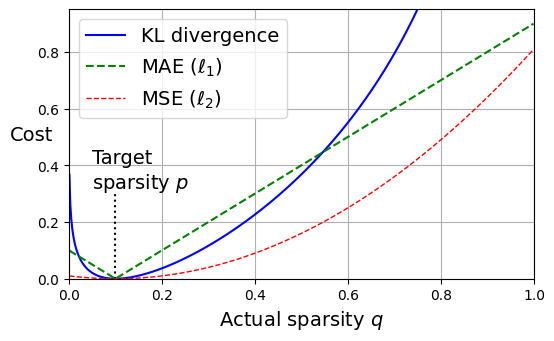

In [46]:
# extra code – this cell generates Figure 18–10
plt.figure(figsize=(6, 3.5))
p = 0.1
q = np.linspace(0.001, 0.999, 500)
kl_div = p * np.log(p / q) + (1 - p) * np.log((1 - p) / (1 - q))
mse_ = (p - q) ** 2
mae = np.abs(p - q)
plt.plot([p, p], [0, 0.3], "k:")
plt.text(0.05, 0.32, "Target\nsparsity $p$", fontsize=14)
plt.plot(q, kl_div, "b-", label="KL divergence")
plt.plot(q, mae, "g--", label=r"MAE ($\ell_1$)")
plt.plot(q, mse_, "r--", linewidth=1, label=r"MSE ($\ell_2$)")
plt.legend(loc="upper left", fontsize=14)
plt.xlabel("Actual sparsity $q$")
plt.ylabel("Cost", rotation=0)
plt.axis([0, 1, 0, 0.95])
plt.grid(True)

Now let's use this regularizer to push the model to have about 10% sparsity in the coding layer:

In [47]:
torch.manual_seed(42)
sparse_ae = SparseAutoencoder().to(device)
optimizer = torch.optim.NAdam(sparse_ae.parameters(), lr=0.002)
history = train(
    sparse_ae,
    optimizer,
    mse_plus_sparsity_loss,
    rmse,
    train_loader,
    valid_loader,
    n_epochs=10,
)

Batch 72/1719, loss=0.0911, train_metric=0.288

Batch 145/1719, loss=0.0701, train_metric=0.255

Batch 217/1719, loss=0.0611, train_metric=0.239

Batch 289/1719, loss=0.0555, train_metric=0.228

Batch 362/1719, loss=0.0510, train_metric=0.219

...

Batch 1541/1719, loss=0.0084, train_metric=0.090

Batch 1621/1719, loss=0.0084, train_metric=0.090

Batch 1701/1719, loss=0.0084, train_metric=0.090

Batch 1719/1719, loss=0.0084, train_metric=0.090

Epoch 10/10,                      train loss: 0.0084, train metric: 0.0905, valid metric: 0.0911


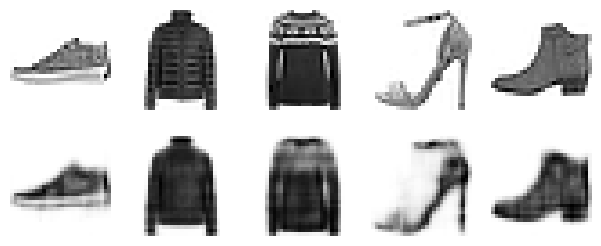

In [48]:
# extra code – shows the reconstructions
plot_reconstructions(sparse_ae, X_valid)
plt.show()

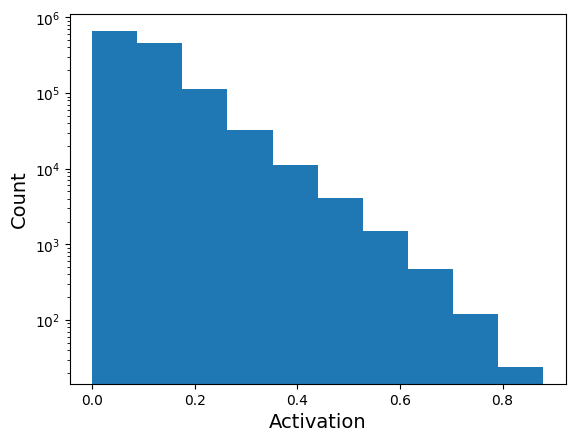

In [49]:
with torch.no_grad():
    y_pred = sparse_ae(X_valid.to(device))

encs = y_pred.codings.flatten().detach().cpu()
plt.hist(encs, log=True)
plt.xlabel("Activation")
plt.ylabel("Count")
plt.show()

In [50]:
y_pred.codings.mean()

tensor(0.1023, device='cuda:0')

Sparse autoencoders often have fairly interpretable codings. For example, here are some images with a high coding #6: they are all shoes (however, it's not always the case when the model is a simple MLP, it's better when the model is a convolutional network).

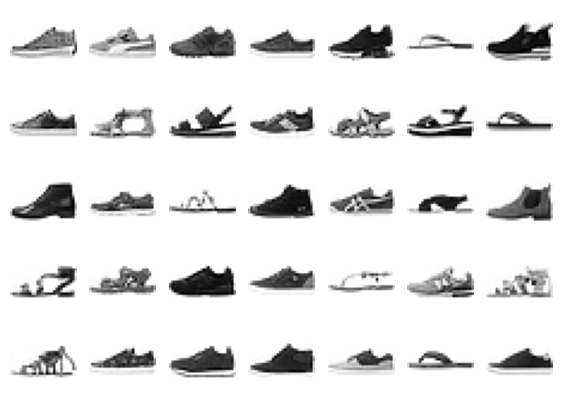

In [51]:
def plot_multiple_images(images, n_cols=None):
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    plt.figure(figsize=(n_cols, n_rows))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plot_image(image)


dim = 6
codings = y_pred.codings[:, dim].cpu()
threshold = np.percentile(codings, 90)
selected_images = X_valid[codings > threshold]
plot_multiple_images(selected_images[:35], 7)
plt.show()

# Variational Autoencoder

In [52]:
VAEOutput = namedtuple("VAEOutput", ["output", "codings_mean", "codings_logvar"])


class VAE(nn.Module):
    def __init__(self, codings_dim=32):
        super(VAE, self).__init__()
        self.codings_dim = codings_dim
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1 * 28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 2 * codings_dim),
        )  # output both the mean and logvar
        self.decoder = nn.Sequential(
            nn.Linear(codings_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1 * 28 * 28),
            nn.Sigmoid(),
            nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
        )

    def encode(self, X):
        return self.encoder(X).chunk(2, dim=-1)  # returns (mean, logvar)

    def sample_codings(self, codings_mean, codings_logvar):
        codings_std = torch.exp(0.5 * codings_logvar)
        noise = torch.randn_like(codings_std)
        return codings_mean + noise * codings_std

    def decode(self, Z):
        return self.decoder(Z)

    def forward(self, X):
        codings_mean, codings_logvar = self.encode(X)
        codings = self.sample_codings(codings_mean, codings_logvar)
        output = self.decode(codings)
        return VAEOutput(output, codings_mean, codings_logvar)

In [53]:
def vae_loss(y_pred, y_target, kl_weight=1.0):
    output, mean, logvar = y_pred
    kl_div = -0.5 * torch.sum(1 + logvar - logvar.exp() - mean.square(), dim=-1)
    return F.mse_loss(output, y_target) + kl_weight * kl_div.mean() / 784

In [54]:
torch.manual_seed(42)
vae = VAE().to(device)
optimizer = torch.optim.NAdam(vae.parameters(), lr=1e-3)
history = train(vae, optimizer, vae_loss, rmse, train_loader, valid_loader, n_epochs=20)

Batch 73/1719, loss=0.1056, train_metric=0.315

Batch 151/1719, loss=0.0856, train_metric=0.280

Batch 225/1719, loss=0.0768, train_metric=0.263

Batch 298/1719, loss=0.0715, train_metric=0.253

Batch 373/1719, loss=0.0678, train_metric=0.245

...

Batch 1531/1719, loss=0.0318, train_metric=0.147

Batch 1605/1719, loss=0.0318, train_metric=0.147

Batch 1677/1719, loss=0.0318, train_metric=0.147

Batch 1719/1719, loss=0.0318, train_metric=0.147

Epoch 20/20,                      train loss: 0.0318, train metric: 0.147, valid metric: 0.148


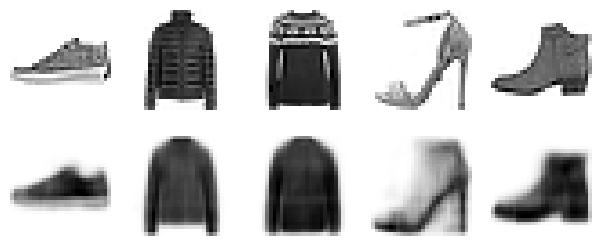

In [55]:
plot_reconstructions(vae, X_valid)
plt.show()

## Generate Fashion Images

Let's generate a few random codings and decode them:

In [56]:
torch.manual_seed(42)  # extra code – ensures reproducibility

vae.eval()
codings = torch.randn(3 * 7, vae.codings_dim, device=device)
with torch.no_grad():
    images = vae.decode(codings)

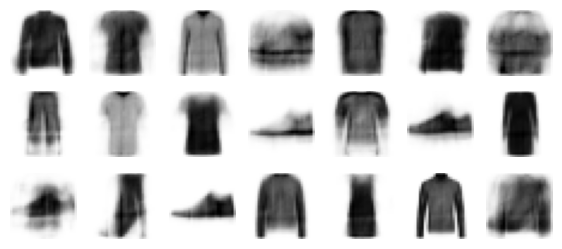

In [57]:
# extra code – this cells generates Figure 18-12

plot_multiple_images(images, 7)

plt.show()

Now let's perform semantic interpolation between 2 images:

In [58]:
codings.shape

torch.Size([21, 32])

In [59]:
torch.manual_seed(111)  # extra code – ensure reproducibility

codings = torch.randn(2, vae.codings_dim)  # start and end codings
n_images = 7
weights = torch.linspace(0, 1, n_images).view(n_images, 1)
codings = torch.lerp(codings[0], codings[1], weights)  # linear interpolation
with torch.no_grad():
    images = vae.decode(codings.to(device))

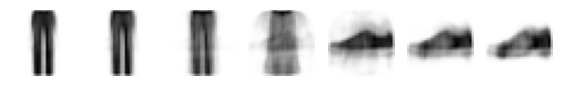

In [60]:
plot_multiple_images(images)

plt.show()

## Discrete VAE

There's a bug in `F.gumbel_softmax()` on MPS devices (see [PyTorch issue #159103](https://github.com/pytorch/pytorch/issues/159103)) so the code below works around it:

In [61]:
def gumbel_softmax(logits, tau=1, hard=False, dim=-1):
    if device != "mps":
        return F.gumbel_softmax(logits, tau=tau, hard=hard, dim=dim)
    gumbels = (
        -torch.empty_like(logits, memory_format=torch.legacy_contiguous_format)
        .exponential_()
        .log()
    )  # ~Gumbel(0,1)
    gumbels = torch.clamp(gumbels, -30, 30)  # <<<<<<<<<<<<<<<<<<<<< ADDED
    gumbels = (logits + gumbels) / tau  # ~Gumbel(logits,tau)
    y_soft = gumbels.softmax(dim)

    if hard:
        # Straight through.
        index = y_soft.max(dim, keepdim=True)[1]
        y_hard = torch.zeros_like(
            logits, memory_format=torch.legacy_contiguous_format
        ).scatter_(dim, index, 1.0)
        ret = y_hard - y_soft.detach() + y_soft
    else:
        # Reparametrization trick.
        ret = y_soft
    return ret

In [62]:
DiscreteVAEOutput = namedtuple(
    "DiscreteVAEOutput", ["output", "logits", "codings_prob"]
)


class DiscreteVAE(nn.Module):
    def __init__(self, coding_length=32, n_codes=16, temperature=1.0):
        super().__init__()
        self.coding_length = coding_length
        self.n_codes = n_codes
        self.temperature = temperature
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1 * 28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, coding_length * n_codes),
            nn.Unflatten(dim=1, unflattened_size=(coding_length, n_codes)),
        )
        self.decoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(coding_length * n_codes, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 1 * 28 * 28),
            nn.Sigmoid(),
            nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
        )

    def forward(self, X):
        logits = self.encoder(X)
        codings_prob = gumbel_softmax(logits, tau=self.temperature, hard=True)
        output = self.decoder(codings_prob)
        return DiscreteVAEOutput(output, logits, codings_prob)

**Note**: when computing the Gumbel-Softmax reparameterization, `hard=True` makes the forward pass use a one-hot sample, but the backward pass uses the soft (differentiable) sample.

In [63]:
def d_vae_loss(y_pred, y_target, kl_weight=1.0):
    output, logits, _ = y_pred
    codings_prob = F.softmax(logits, -1)
    k = logits.new_tensor(logits.size(-1))  # same device and dtype as logits
    kl_div = (codings_prob * (codings_prob.log() + k.log())).sum(dim=(1, 2))
    return F.mse_loss(output, y_target) + kl_weight * kl_div.mean() / 784

In [64]:
n_epochs = 20


def annealing(model, epoch):
    model.temperature = 1 - 0.9 * epoch / n_epochs


torch.manual_seed(42)
d_vae = DiscreteVAE().to(device)
optimizer = torch.optim.NAdam(d_vae.parameters(), lr=0.001)
history = train(
    d_vae,
    optimizer,
    d_vae_loss,
    rmse,
    train_loader,
    valid_loader,
    n_epochs=n_epochs,
    epoch_callback=annealing,
)

./.venv/lib/python3.12/site-packages/torch/nn/functional.py:2194: UserWarning: `eps` parameter is deprecated and has no effect.
  warnings.warn("`eps` parameter is deprecated and has no effect.")


Batch 25/1719, loss=0.1194, train_metric=0.345

Batch 93/1719, loss=0.0953, train_metric=0.308

Batch 164/1719, loss=0.0870, train_metric=0.292

Batch 234/1719, loss=0.0825, train_metric=0.284

...

Batch 1522/1719, loss=0.0363, train_metric=0.168

Batch 1596/1719, loss=0.0362, train_metric=0.168

Batch 1670/1719, loss=0.0362, train_metric=0.168

Batch 1719/1719, loss=0.0362, train_metric=0.168

Epoch 20/20,                      train loss: 0.0362, train metric: 0.168, valid metric: 0.169


In [65]:
torch.manual_seed(42)  # extra code – ensures reproducibility
n_images = 3 * 7
codings = torch.randint(
    0,
    d_vae.n_codes,  # from 0 to k – 1
    (n_images, d_vae.coding_length),
    device=device,
)
codings_prob = F.one_hot(codings, num_classes=d_vae.n_codes).float()
with torch.no_grad():
    images = d_vae.decoder(codings_prob)

Now let's plot these images:

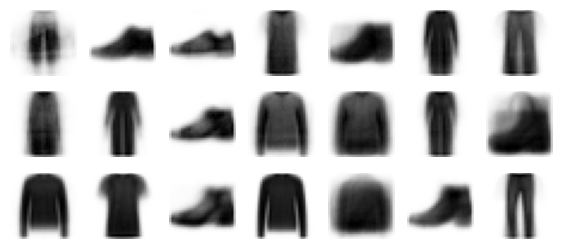

In [66]:
plot_multiple_images(images, 7)
plt.show()

# Generative Adversarial Networks

In [67]:
torch.manual_seed(42)  # extra code – ensures reproducibility

codings_dim = 32
generator = nn.Sequential(
    nn.Linear(codings_dim, 128),
    nn.ReLU(),
    nn.Linear(128, 256),
    nn.ReLU(),
    nn.Linear(256, 1 * 28 * 28),
    nn.Sigmoid(),
    nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
).to(device)
discriminator = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1 * 28 * 28, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 1),
    nn.Sigmoid(),
).to(device)

In [68]:
def train_gan(
    generator,
    discriminator,
    train_loader,
    codings_dim,
    n_epochs=20,
    g_lr=1e-3,
    d_lr=5e-4,
):
    criterion = nn.BCELoss()
    generator_opt = torch.optim.NAdam(generator.parameters(), lr=g_lr)
    discriminator_opt = torch.optim.NAdam(discriminator.parameters(), lr=d_lr)
    for epoch in range(n_epochs):
        print(f"Epoch {epoch + 1}/{n_epochs}", end="")
        for real_images, _ in train_loader:
            real_images = real_images.to(device)
            pred_real = discriminator(real_images)
            batch_size = real_images.size(0)
            ones = torch.ones(batch_size, 1, device=device)
            real_loss = criterion(pred_real, ones)
            codings = torch.randn(batch_size, codings_dim, device=device)
            fake_images = generator(codings).detach()
            pred_fake = discriminator(fake_images)
            zeros = torch.zeros(batch_size, 1, device=device)
            fake_loss = criterion(pred_fake, zeros)
            discriminator_loss = real_loss + fake_loss
            discriminator_opt.zero_grad()
            discriminator_loss.backward()
            discriminator_opt.step()

            codings = torch.randn(batch_size, codings_dim, device=device)
            fake_images = generator(codings)
            for p in discriminator.parameters():
                p.requires_grad = False
            pred_fake = discriminator(fake_images)
            generator_loss = criterion(pred_fake, ones)
            generator_opt.zero_grad()
            generator_loss.backward()
            generator_opt.step()
            for p in discriminator.parameters():
                p.requires_grad = True
        print(f" | discriminator loss: {discriminator_loss.item():.4f}", end="")
        print(f" | generator loss: {generator_loss.item():.4f}")
        if epoch % 10 == 0 or epoch == n_epochs - 1:
            plot_multiple_images(fake_images.detach(), 8)
            plt.show()

Epoch 1/20

 | discriminator loss: 0.3696 | generator loss: 2.8922


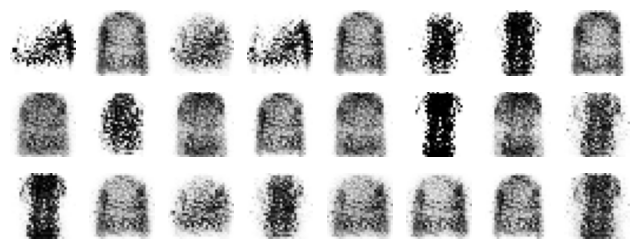

Epoch 2/20

 | discriminator loss: 0.9720 | generator loss: 1.3685
Epoch 3/20

 | discriminator loss: 0.6460 | generator loss: 1.9944
Epoch 4/20

 | discriminator loss: 1.2112 | generator loss: 0.8882
Epoch 5/20

 | discriminator loss: 0.8049 | generator loss: 2.0310
Epoch 6/20

...

 | discriminator loss: 0.4771 | generator loss: 2.0667
Epoch 8/20

 | discriminator loss: 0.4828 | generator loss: 1.7278
Epoch 9/20

 | discriminator loss: 0.8652 | generator loss: 2.5256
Epoch 10/20

 | discriminator loss: 0.5683 | generator loss: 1.6799
Epoch 11/20

 | discriminator loss: 0.8162 | generator loss: 1.8824


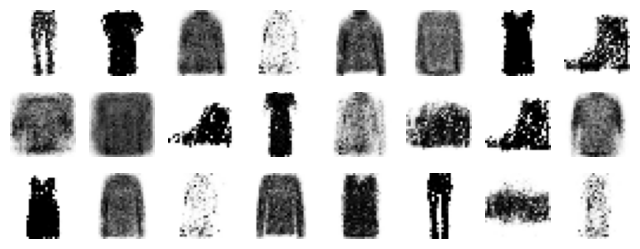

Epoch 12/20

 | discriminator loss: 0.6233 | generator loss: 2.1129
Epoch 13/20

 | discriminator loss: 0.7629 | generator loss: 2.0465
Epoch 14/20

 | discriminator loss: 0.8912 | generator loss: 1.7095
Epoch 15/20

 | discriminator loss: 1.0950 | generator loss: 1.2333
Epoch 16/20

 | discriminator loss: 0.8589 | generator loss: 1.5880
Epoch 17/20

 | discriminator loss: 1.1486 | generator loss: 1.2391
Epoch 18/20

 | discriminator loss: 1.0887 | generator loss: 1.0477
Epoch 19/20

 | discriminator loss: 1.1702 | generator loss: 1.1355
Epoch 20/20

 | discriminator loss: 0.9890 | generator loss: 1.6049


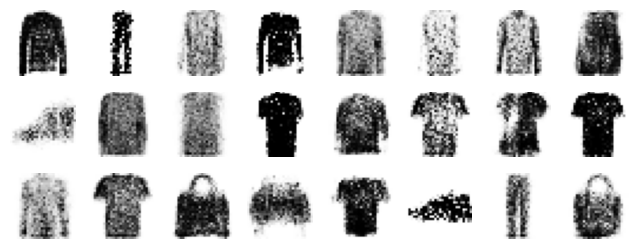

In [69]:
torch.manual_seed(41)  # trying another seed often fixes the issue 😅
train_gan(generator, discriminator, train_loader, codings_dim)

In [70]:
torch.manual_seed(42)  # extra code – ensures reproducibility
n_images = 3 * 7
generator.eval()
codings = torch.randn(n_images, codings_dim, device=device)
with torch.no_grad():
    generated_images = generator(codings)

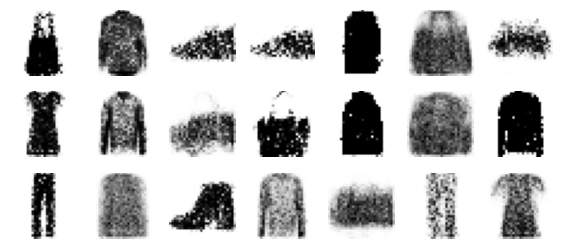

In [71]:
# extra code – this cell generates Figure 18–15
plot_multiple_images(generated_images, 7)

plt.show()

# Deep Convolutional GAN

In [72]:
torch.manual_seed(1)  # extra code – ensures reproducibility

dc_codings_dim = 100

dc_generator = nn.Sequential(
    nn.Linear(dc_codings_dim, 128 * 7 * 7),
    nn.Unflatten(dim=1, unflattened_size=(128, 7, 7)),
    nn.BatchNorm2d(128),
    nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
    nn.ReLU(),
    nn.BatchNorm2d(64),
    nn.ConvTranspose2d(64, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
    nn.Sigmoid(),
).to(device)
dc_discriminator = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=5, stride=2, padding=2),
    nn.ReLU(),  # 32 x 14 x 14
    nn.Dropout(0.4),
    nn.Conv2d(32, 64, kernel_size=5, stride=2, padding=2),
    nn.ReLU(),  # 64 x 7 x 7
    nn.Dropout(0.4),
    nn.Flatten(),
    nn.Linear(64 * 7 * 7, 1),
    nn.Sigmoid(),
).to(device)

Epoch 1/20

 | discriminator loss: 1.5003 | generator loss: 0.9649


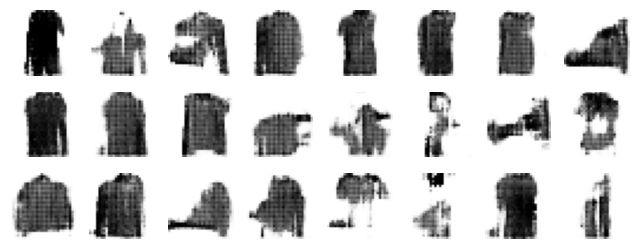

Epoch 2/20

 | discriminator loss: 0.9684 | generator loss: 1.1961
Epoch 3/20

 | discriminator loss: 0.7824 | generator loss: 1.2399
Epoch 4/20

 | discriminator loss: 0.9654 | generator loss: 1.1767
Epoch 5/20

 | discriminator loss: 1.0663 | generator loss: 1.0408
Epoch 6/20

...

 | discriminator loss: 0.7917 | generator loss: 1.2793
Epoch 8/20

 | discriminator loss: 0.8617 | generator loss: 1.6344
Epoch 9/20

 | discriminator loss: 0.7001 | generator loss: 1.5575
Epoch 10/20

 | discriminator loss: 0.6613 | generator loss: 1.5981
Epoch 11/20

 | discriminator loss: 0.9141 | generator loss: 1.7379


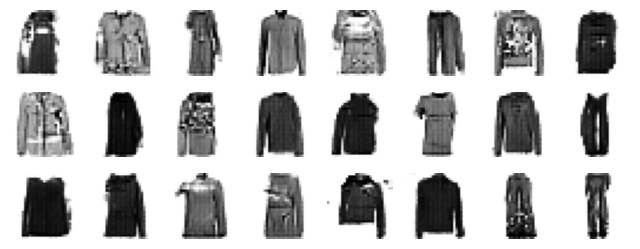

Epoch 12/20

 | discriminator loss: 0.9175 | generator loss: 1.9802
Epoch 13/20

 | discriminator loss: 0.8683 | generator loss: 1.2822
Epoch 14/20

 | discriminator loss: 0.7016 | generator loss: 1.4460
Epoch 15/20

 | discriminator loss: 0.5219 | generator loss: 1.5705
Epoch 16/20

 | discriminator loss: 0.5862 | generator loss: 1.5329
Epoch 17/20

 | discriminator loss: 0.6229 | generator loss: 1.6206
Epoch 18/20

 | discriminator loss: 0.4187 | generator loss: 1.6910
Epoch 19/20

 | discriminator loss: 0.6761 | generator loss: 1.9029
Epoch 20/20

 | discriminator loss: 0.6753 | generator loss: 2.0154


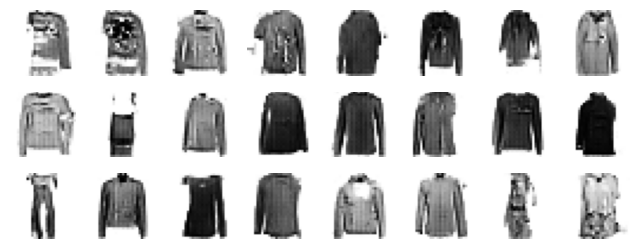

In [73]:
torch.manual_seed(42)
train_gan(dc_generator, dc_discriminator, train_loader, dc_codings_dim)

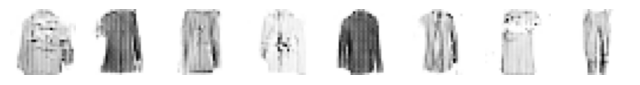

In [74]:
# extra code – this cell generates Figure 18–16
torch.manual_seed(42)
with torch.no_grad():
    codings = torch.randn(8, dc_codings_dim, device=device)
    generated_images = dc_generator(codings)

plot_multiple_images(generated_images, 8)

# Diffusion Models

Starting with an image from the dataset, at each time step $t$, the diffusion process adds Gaussian noise with mean 0 and variance $\beta_t$. The model is then trained to reverse that process. More specifically, given a noisy image produced by the forward process, and given the time $t$, the model is trained to predict the total noise that was added to the original image, scaled to variance 1.

The [DDPM paper](https://arxiv.org/abs/2006.11239) increased $\beta_t$ from $\beta_1$ = 0.0001 to $\beta_T = $0.02 ($T$ is the max step), but the [Improved DDPM paper](https://arxiv.org/pdf/2102.09672.pdf) suggested using the following $\cos^2(\ldots)$ schedule instead, which gradually decreases $\bar{\alpha_t} = \prod_{i=0}^{t} \alpha_i$ from 1 to 0, where $\alpha_t = 1 - \beta_t$:

In [75]:
def variance_schedule(T, s=0.008, max_beta=0.999):
    t = torch.linspace(0, T, T + 1)
    f = torch.cos((t / T + s) / (1 + s) * torch.pi / 2) ** 2
    alpha_bars = f / f[0]
    betas = (1 - (f[1:] / f[:-1])).clamp(max=max_beta)
    betas = torch.cat([torch.zeros(1), betas])  # for easier indexing
    alphas = 1 - betas
    return alphas, betas, alpha_bars


torch.manual_seed(42)  # extra code – for reproducibility
T = 4000
alphas, betas, alpha_bars = variance_schedule(T)

In the DDPM paper, the authors used $T = 1,000$, while in the Improved DDPM, they bumped this up to $T = 4,000$, so we use this value. The variables `alphas`, `betas`, and `alpha_bars` contain $\alpha_t$, $\beta_t$, $\bar{\alpha}_t$ respectively, starting from _t_ = 0.

Let's plot `alpha_bars`:

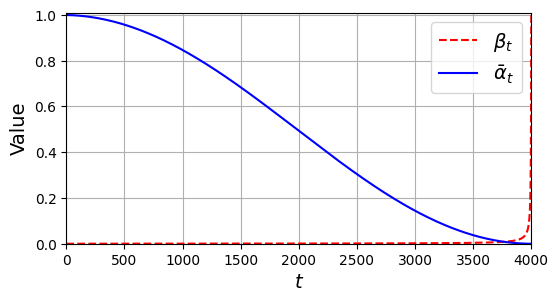

In [76]:
# extra code – this cell generates Figure 18–21
plt.figure(figsize=(6, 3))
plt.plot(betas, "r--", label=r"$\beta_t$")
plt.plot(alpha_bars, "b", label=r"$\bar{\alpha}_t$")
plt.axis([0, T, 0, 1.01])
plt.grid(True)
plt.xlabel("$t$")
plt.ylabel(r"Value")
plt.legend()

plt.show()

The following function uses equation (4) from the DDPM paper to compute the noisy images in one shot, directly from the original images. It's a shortcut for the forward diffusion process.

In [77]:
def forward_diffusion(x0, t):
    eps = torch.randn_like(x0)  # this unscaled noise will be the target
    xt = alpha_bars[t].sqrt() * x0 + (1 - alpha_bars[t]).sqrt() * eps
    return xt, eps

Each input is a `DiffusionSample` instance containing the noisy image, and the corresponding time step.

In [78]:
class DiffusionSample(namedtuple("DiffusionSampleBase", ["xt", "t"])):
    def to(self, device):
        return DiffusionSample(self.xt.to(device), self.t.to(device))

The `DiffusionDataset` function takes an image dataset, and for each image, it scales the pixel values between –1 and +1, then picks a random time step between 1 and _T_ and adds the corresponding noise, then it returns a tuple with the input and the target. The input is a `DiffusionSample`, and the target is the unscaled noise `eps`:

In [79]:
class DiffusionDataset:
    def __init__(self, dataset):
        self.dataset = dataset

    def __getitem__(self, i):
        x0, _ = self.dataset[i]
        x0 = (x0 * 2) - 1  # scale from –1 to +1
        t = torch.randint(1, T + 1, size=[1])
        xt, eps = forward_diffusion(x0, t)
        return DiffusionSample(xt, t), eps

    def __len__(self):
        return len(self.dataset)


train_set = DiffusionDataset(train_data)  # wrap Fashion MNIST
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)

In [80]:
valid_set = DiffusionDataset(valid_data)
valid_loader = DataLoader(valid_set, batch_size=32)

As a quick sanity check, let's take a look at a few training samples, along with the corresponding noise to predict, and the original images (which we get by subtracting the appropriately scaled noise from the appropriately scaled noisy image):

Original images


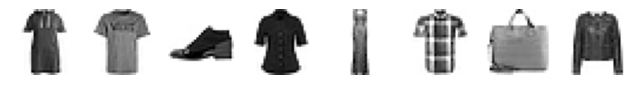

Time steps: [2027, 1463, 3720, 9, 611, 2202, 2118, 388]
Noisy images


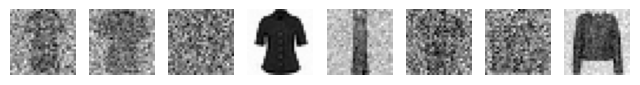

Noise to predict


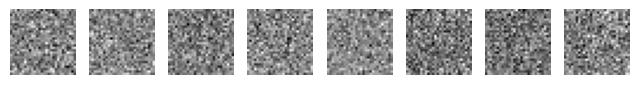

In [81]:
# extra code – just a quick sanity check


def original_image(sample, noise):
    alpha_bars_t = torch.gather(alpha_bars, dim=0, index=sample.t.squeeze(1))
    alpha_bars_t = alpha_bars_t.view(-1, 1, 1, 1)
    x0 = (sample.xt - (1 - alpha_bars_t).sqrt() * noise) / alpha_bars_t.sqrt()
    return torch.clamp((x0 + 1) / 2, 0, 1)


torch.manual_seed(42)
sample, eps = next(iter(train_loader))  # get the first batch
x0 = original_image(sample, eps).to(device)

print("Original images")
plot_multiple_images(x0[:8])
plt.show()
print("Time steps:", sample.t[:8].view(-1).tolist())
print("Noisy images")
plot_multiple_images(sample.xt[:8])
plt.show()
print("Noise to predict")
plot_multiple_images(eps[:8])
plt.show()

Now we're ready to build the diffusion model itself. It will need to process both images and times. We will encode the times using a sinusoidal encoding, as suggested in the DDPM paper, just like in the [Attention is all you need](https://arxiv.org/abs/1706.03762) paper. Given a vector of _m_ integers representing time indices (integers), the layer returns an _m_ × _d_ matrix, where _d_ is the chosen embedding size.

In [82]:
# extra code – implements a custom time encoding layer

embed_dim = 64


class TimeEncoding(nn.Module):
    def __init__(self, T, embed_dim):
        super().__init__()
        assert embed_dim % 2 == 0, "embed_dim must be even"
        p = torch.arange(T + 1).unsqueeze(1)
        angle = p / 10_000 ** (torch.arange(0, embed_dim, 2) / embed_dim)
        te = torch.empty(T + 1, embed_dim)
        te[:, 0::2] = torch.sin(angle)
        te[:, 1::2] = torch.cos(angle)
        self.register_buffer("time_encodings", te)

    def forward(self, t):
        return self.time_encodings[t]

Now let's build the model. In the Improved DDPM paper, they use a UNet model. We'll create a UNet-like model, that processes the image through `Conv2d` + `BatchNorm2d` layers and skip connections, gradually downsampling the image (using `MaxPool2d` layers with `stride=2`), then growing it back again (using `Upsample` layers). Skip connections are also added across the downsampling part and the upsampling part. We also add the time encodings to the output of each block, after passing them through a `Linear` layer to resize them to the right dimension.

* **Note**: an image's time encoding is added to every pixel in the image, along the last axis (channels). So the number of units in the `Conv2d` layer must correspond to the embedding size, and we must reshape the `time_enc` tensor to add the width and height dimensions.
* This UNet implementation was inspired by keras.io's [image segmentation example](https://keras.io/examples/vision/oxford_pets_image_segmentation/), as well as from the [official diffusion models implementation](https://github.com/hojonathanho/diffusion/blob/master/diffusion_tf/models/unet.py). Compared to the first implementation, I added a few things, especially time encodings and skip connections across down/up parts. Compared to the second implementation, I removed a few things, especially the attention layers. It seemed like overkill for Fashion MNIST, but feel free to add them.

In [83]:
class SeparableConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, padding):
        super().__init__()
        self.depthwise = nn.Conv2d(
            in_channels, in_channels, kernel_size, padding=padding, groups=in_channels
        )
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1)

    def forward(self, X):
        return self.pointwise(self.depthwise(X))


class DiffusionModel(nn.Module):
    def __init__(self, T=T, embed_dim=64):
        super().__init__()
        self.time_encoding = TimeEncoding(T, embed_dim)

        # Init
        dim = 16
        self.pad = nn.ConstantPad2d((3, 3, 3, 3), 0)
        self.init_conv = nn.Conv2d(1, dim, kernel_size=3)
        self.init_bn = nn.BatchNorm2d(dim)
        self.time_adapter_init = nn.Linear(embed_dim, dim)

        # Down path
        self.down_blocks = nn.ModuleList()
        self.skip_convs = nn.ModuleList()
        self.time_adapters_down = nn.ModuleList()
        in_dim = dim
        for dim in (32, 64, 128):
            block = nn.Sequential(
                nn.ReLU(),
                SeparableConv2d(in_dim, dim, kernel_size=3, padding=1),
                nn.BatchNorm2d(dim),
                nn.ReLU(),
                SeparableConv2d(dim, dim, kernel_size=3, padding=1),
                nn.BatchNorm2d(dim),
            )
            skip_conv = nn.Conv2d(in_dim, dim, kernel_size=1, stride=2)
            self.down_blocks.append(block)
            self.skip_convs.append(skip_conv)
            self.time_adapters_down.append(nn.Linear(embed_dim, dim))
            in_dim = dim

        # Up path
        self.up_blocks = nn.ModuleList()
        self.skip_up_convs = nn.ModuleList()
        self.time_adapters_up = nn.ModuleList()
        for dim in (64, 32, 16):
            block = nn.Sequential(
                nn.ReLU(),
                nn.ConvTranspose2d(in_dim, dim, 3, padding=1),
                nn.BatchNorm2d(dim),
                nn.ReLU(),
                nn.ConvTranspose2d(dim, dim, 3, padding=1),
                nn.BatchNorm2d(dim),
            )
            skip_conv = nn.Conv2d(in_dim, dim, kernel_size=1)
            self.up_blocks.append(block)
            self.skip_up_convs.append(skip_conv)
            self.time_adapters_up.append(nn.Linear(embed_dim, dim))
            in_dim = dim * 3  # because of concatenation with cross skip

        self.final_conv = nn.Conv2d(in_dim, 1, 3, padding=1)

    def forward(self, sample):
        if not isinstance(sample, DiffusionSample):
            print(repr(sample))
        time_enc = self.time_encoding(sample.t.squeeze(1))  # [batch, embed_dim]
        z = self.pad(sample.xt)
        z = F.relu(self.init_bn(self.init_conv(z)))
        z = z + self.time_adapter_init(time_enc)[:, :, None, None]
        skip = z
        cross_skips = []

        # Downsampling path
        for block, skip_conv, time_adapter in zip(
            self.down_blocks, self.skip_convs, self.time_adapters_down
        ):
            z = block(z)
            cross_skips.append(z)
            z = F.max_pool2d(z, 3, stride=2, padding=1)
            skip_link = skip_conv(skip)
            z = z + skip_link
            z = z + time_adapter(time_enc)[:, :, None, None]
            skip = z

        # Upsampling path
        for block, skip_up_conv, time_adapter in zip(
            self.up_blocks, self.skip_up_convs, self.time_adapters_up
        ):
            z = block(z)
            z = F.interpolate(z, scale_factor=2, mode="nearest")
            skip_link = F.interpolate(skip, scale_factor=2, mode="nearest")
            skip_link = skip_up_conv(skip_link)
            z = z + skip_link
            z = z + time_adapter(time_enc)[:, :, None, None]
            cross_skip = cross_skips.pop()
            z = torch.cat([z, cross_skip], dim=1)
            skip = z

        out = self.final_conv(z)
        out = out[:, :, 2:-2, 2:-2]  # cropping
        return out.contiguous()

Now let's train the model!

In [84]:
torch.manual_seed(42)
diffusion_model = DiffusionModel().to(device)
huber = nn.HuberLoss()
optimizer = torch.optim.NAdam(diffusion_model.parameters(), lr=3e-3)
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train(
    diffusion_model, optimizer, huber, rmse, train_loader, valid_loader, n_epochs=20
)

Batch 14/1719, loss=0.2560, train_metric=0.759

Batch 28/1719, loss=0.1944, train_metric=0.656

Batch 43/1719, loss=0.1687, train_metric=0.608

Batch 58/1719, loss=0.1530, train_metric=0.578

Batch 73/1719, loss=0.1459, train_metric=0.564

...

Batch 1634/1719, loss=0.0389, train_metric=0.288

Batch 1664/1719, loss=0.0389, train_metric=0.288

Batch 1693/1719, loss=0.0389, train_metric=0.288

Batch 1719/1719, loss=0.0389, train_metric=0.288

Epoch 20/20,                      train loss: 0.0389, train metric: 0.288, valid metric: 0.285


Now that the model is trained, we can use it to generate new images. For this, we just generate Gaussian noise, and pretend this is the result of the diffusion process, and we're at time $T$. Then we use the model to predict the image at time $T - 1$, then we call it again to get $T - 2$, and so on, removing a bit of noise at each step. At the end, we get an image that looks like it's from the Fashion MNIST dataset. The equation for this reverse process is at the top of page 4 in the DDPM paper (step 4 in algorithm 2).

In [85]:
def generate_ddpm(model, batch_size=32):
    model.eval()
    with torch.no_grad():
        xt = torch.randn([batch_size, 1, 28, 28], device=device)
        for t in range(T, 0, -1):
            print(f"\rt = {t}", end=" ")  # extra code — show progress
            alpha_t = alphas[t]
            beta_t = betas[t]
            alpha_bar_t = alpha_bars[t]
            noise = (
                torch.randn(xt.shape, device=device)
                if t > 1
                else torch.zeros(xt.shape, device=device)
            )
            t_batch = torch.full((batch_size, 1), t, device=device)
            sample = DiffusionSample(xt, t_batch)
            eps_pred = model(sample)
            xt = (
                1 / alpha_t.sqrt() * (xt - beta_t / (1 - alpha_bar_t).sqrt() * eps_pred)
                + (1 - alpha_t).sqrt() * noise
            )
        return torch.clamp((xt + 1) / 2, 0, 1)


torch.manual_seed(42)  # extra code – ensures reproducibility
X_gen = generate_ddpm(diffusion_model)  # generated images

t = 3778 

t = 3774 

t = 3547 

t = 3545 

t = 3314 

...

t = 765 

t = 532 

t = 300 

t = 67 

t = 1 

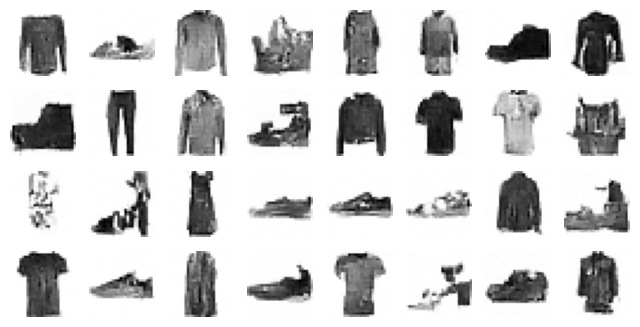

In [86]:
plot_multiple_images(X_gen, 8)
plt.show()

Some of these images are really convincing! Compared to GANs, diffusion models tend to generate more diverse images, and they have surpassed GANs in image quality. Moreover, training is much more stable. However, generating images takes *much* longer.

In [87]:
def generate_ddim(model, batch_size=32, num_steps=50, eta=0.85):
    model.eval()
    with torch.no_grad():
        xt = torch.randn([batch_size, 1, 28, 28], device=device)
        times = torch.linspace(T - 1, 0, steps=num_steps + 1).long().tolist()
        for t, t_prev in zip(times[:-1], times[1:]):
            print(f"\rt = {t}", end=" ")
            t_batch = torch.full((batch_size, 1), t, device=device)
            sample = DiffusionSample(xt, t_batch)
            eps_pred = model(sample)
            x0 = (xt - (1 - alpha_bars[t]).sqrt() * eps_pred) / (alpha_bars[t].sqrt())
            abar_t_prev = alpha_bars[t_prev]
            variance = eta * (1 - abar_t_prev) / (1 - alpha_bars[t]) * betas[t]
            sigma_t = variance.sqrt()
            pred_dir = (1 - abar_t_prev - sigma_t**2).sqrt() * eps_pred
            noise = torch.randn_like(xt)
            xt = abar_t_prev.sqrt() * x0 + pred_dir + sigma_t * noise

        return torch.clamp((xt + 1) / 2, 0, 1)  # from [–1, 1] range to [0, 1]


torch.manual_seed(42)  # extra code – ensures reproducibility
X_gen_ddim = generate_ddim(diffusion_model, num_steps=500)

t = 2255 

t = 487 

t = 7 

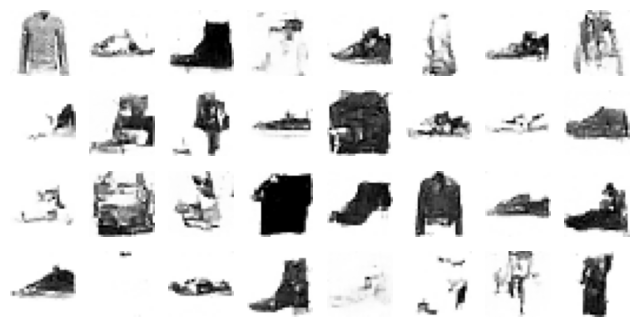

In [88]:
plot_multiple_images(X_gen_ddim, 8)
plt.show()

In [89]:
from diffusers import AutoPipelineForText2Image

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo", variant="fp16", dtype=torch.float16
)
pipe.to(device)
prompt = "A closeup photo of an orangutan reading a book"

Keyword arguments {'dtype': torch.float16} are not expected by StableDiffusionPipeline and will be ignored.


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/1 [00:00<?, ?it/s]

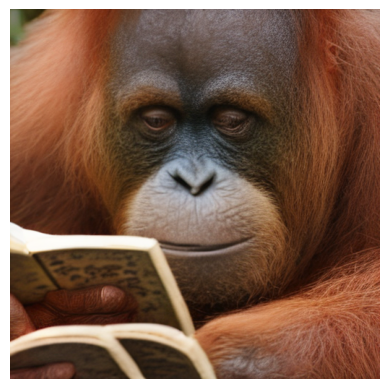

In [90]:
torch.manual_seed(42)
image = pipe(prompt=prompt, num_inference_steps=1, guidance_scale=0.0).images[0]
image.save("my_orangutan_reading.png")
plt.imshow(image)
plt.axis("off")
plt.show()

# Extra Material: Flow Matching

Flow matching was introduced in a [2022 paper](https://arxiv.org/pdf/2210.02747) by Yaron Lipman and other researchers from Meta AI and the Weizmann Institute of Science. It is quickly gaining traction as an alternative to diffusion models. It is faster, requires less compute for similar or better image quality, and it is deterministic.

For a quick intro to flow matching and a comparison with diffusion models, check out this nice [video by Letitia Parcalabescu](https://www.youtube.com/watch?v=firXjwZ_6KI) (AI Coffee Break with Letitia).

In short, for each training image $\mathbf{x}_1$ we define $\mathbf{x}_t$ as a linear interpolation from Gaussian noise ($\mathbf{x}_0$) to that training image $\mathbf{x}_1$. Specifically, $\mathbf{x}_t = (1-t) \, \mathbf{x}_0 + t \, \mathbf{x}_1$. We then train the network to predict the velocity $\mathbf{v}(\mathbf{x}_t, t) = \mathbf{x}_1 - \mathbf{x}_0$. To sample a new image after training, we integrate $\dfrac{d\mathbf{x}}{dt} = \mathbf{v}(\mathbf{x}_t, t)$ from $t=0$ to $t=1$


Let's create a simple implementation of flow matching. First, we need to create the datasets and data loaders:

In [91]:
FlowMatchingSample = DiffusionSample  # we can simply reuse this class!


class FlowDataset:
    def __init__(self, dataset):
        self.dataset = dataset

    def __getitem__(self, i):
        x1, _ = self.dataset[i]
        x1 = (x1 * 2) - 1  # scale from –1 to 1
        x0 = torch.randn_like(x1)  # Gaussian noise
        t = torch.randint(1, T + 1, size=[1])
        t_cont = t / T  # t_cont ranges from 0 to 1
        xt = (1 - t_cont) * x0 + t_cont * x1  # linear interpolation
        velocity = x1 - x0
        return FlowMatchingSample(xt, t), velocity

    def __len__(self):
        return len(self.dataset)


train_set = FlowDataset(train_data)
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)

valid_set = FlowDataset(valid_data)
valid_loader = DataLoader(valid_set, batch_size=32)

The good news is that we can actually reuse both the `DiffusionSample` and the `DiffusionModel` classes! Indeed, a flow matching model takes a noisy image as input, along with the time _t_, just like a diffusion model. It outputs a velocity, which has the same shape as the diffusion model's output: i.e., the same shape as the input image. So we're ready to train the model. That didn't take long! 😄

In [92]:
FlowMatchingModel = DiffusionModel  # we can also reuse this class!

torch.manual_seed(42)
flow_model = FlowMatchingModel().to(device)
optimizer = torch.optim.NAdam(flow_model.parameters(), lr=4e-3)
history = train(
    flow_model, optimizer, huber, rmse, train_loader, valid_loader, n_epochs=10
)

Batch 30/1719, loss=0.3893, train_metric=0.967

Batch 59/1719, loss=0.3318, train_metric=0.882

Batch 89/1719, loss=0.3007, train_metric=0.834

Batch 118/1719, loss=0.2815, train_metric=0.804

Batch 147/1719, loss=0.2672, train_metric=0.782

...

Batch 1640/1719, loss=0.1241, train_metric=0.522

Batch 1667/1719, loss=0.1241, train_metric=0.522

Batch 1694/1719, loss=0.1241, train_metric=0.522

Batch 1719/1719, loss=0.1240, train_metric=0.522

Epoch 10/10,                      train loss: 0.1240, train metric: 0.522, valid metric: 0.519


Now let's write a little function that will generate new images using Euler's method (a basic integration method):

In [93]:
def sample_flow(model, n_samples=32, n_steps=100, device=device):
    model.eval()
    x = torch.randn(n_samples, 1, 28, 28, device=device)
    for i in range(n_steps):
        with torch.no_grad():
            t_int = torch.full(
                (n_samples, 1), int(i / n_steps * T), dtype=torch.long, device=device
            )
            velocity = model(FlowMatchingSample(x, t_int))
            x = x + velocity / n_steps

    return x.clamp(-1, 1)

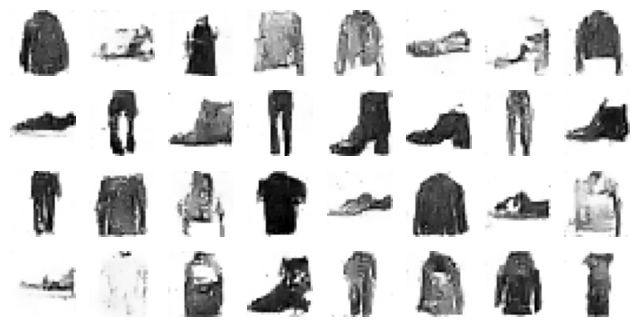

In [94]:
torch.manual_seed(42)
X_gen_flow = sample_flow(flow_model)
plot_multiple_images(X_gen_flow, 8)
plt.show()

# Exercise Solutions

## Work in progress

I'm working on the exercise solutions. Thanks for your patience!